# Notebook 8 - One pooled model and an unseen-route experiment

**Two questions:** (A) can one shared model predict later arrivals on our four known routes? (B) can a model trained on other routes transfer to a route it never learned from?

Put the four original route Excel workbooks and `RTS_GTFS_Spring2023.zip` beside this notebook. No earlier notebook, prepared CSV, or external Python helper is required. Executed results, explanations, plots, and a prediction example are included.

**This is exploratory.** The evaluation outcomes were examined in earlier project runs. Notebook 9 now consolidates those results. We reuse them for a clearly labeled extension, not a new independent confirmation. Schedule assignments remain provisional. No search or tuning uses their errors.

| Experiment | Inputs | What it can establish |
|---|---|---|
| A: known-route pooled model | Route, route-specific direction, stop, hour, weekday | How one fit compares with the four existing separate fits on later dates |
| B: route held out | Shared schedule/location features; no route ID or raw direction code | Transfer to an excluded route at the sampled locations |

The four datasets cover just **three physical stop IDs**. An excluded route is therefore not necessarily a new location or a new transport system.

All forests use the previous fixed settings (300 trees, depth 4, minimum leaf size 10, seed 42). The primary pooled/transfer fits give source routes equal total training weight, to avoid the largest sample dominating. This is a declared design choice, not a weight chosen using evaluation errors. No extra tuning is performed.

**Added metric guide:** after the graphs, find focused pooled and validation-winner tables with test MAE/RMSE, ±2-minute accuracy, R², timetable-relative reductions in minutes/seconds/percent, and a worked explanation. Development adjusted R² is shown only for the linear regression.

**Final project reading order:** this is Notebook 8. Continue to **Notebook 9 — Final Evaluation and Conclusions** for the closing results and reliability summary. The sequence has been reorganized for presentation; it does not change which outcomes were previously inspected.

## 1. Load libraries and fix the setup

Direction codes are route-specific. We create `route_direction`, such as `7:0`, rather than assume every direction 0 has the same geographic meaning. Original bus IDs, actual arrivals, outlier flags, and matching fields remain audit information, not model inputs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile, json, hashlib
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

ROUTES = {
    "7": {"file":"RTS_Route7_March2023.xlsx", "development_days":13, "expected_development_labels":304,
          "features":["direction_id","scheduled_hour","weekday"]},
    "3": {"file":"RTS_Route3_Spring2023.xlsx", "development_days":13, "expected_development_labels":196,
          "features":["direction_id","scheduled_hour","weekday"]},
    "11": {"file":"RTS_Route11_Spring2023.xlsx", "development_days":13, "expected_development_labels":781,
           "features":["direction_id","scheduled_hour","weekday","stop_id"]},
    "711": {"file":"RTS_Route711_Spring2023.xlsx", "development_days":6, "expected_development_labels":110,
            "features":["direction_id","scheduled_hour"]}
}
FOREST_SETTINGS = {"n_estimators":300,"max_depth":4,"min_samples_leaf":10,"random_state":42,"n_jobs":1}

from sklearn.impute import SimpleImputer
import joblib
POOLED_FEATURES = ["route", "route_direction", "stop_id", "scheduled_hour", "weekday"]
POOLED_CATEGORIES = ["route", "route_direction", "stop_id", "weekday"]
print("Fixed forest settings:", FOREST_SETTINGS)
print("Primary pooled predictors:", POOLED_FEATURES)

Fixed forest settings: {'n_estimators': 300, 'max_depth': 4, 'min_samples_leaf': 10, 'random_state': 42, 'n_jobs': 1}
Primary pooled predictors: ['route', 'route_direction', 'stop_id', 'scheduled_hour', 'weekday']


## 2. Reproduce the earlier data handling

The next support cell contains the same frozen route-specific preparation used throughout the route notebooks. It checks original development counts, keeps held records separately, excludes terminals, and preserves Route 711's different numbering. It does not choose a cleaning rule based on model error.

You can focus on the following coverage table first; the function definitions support reproducibility rather than introduce a new cleaning lesson.

In [2]:
def read_gtfs(name):
    with zipfile.ZipFile('RTS_GTFS_Spring2023.zip') as archive:
        table = pd.read_csv(archive.open(name), dtype=str, keep_default_na=False)
    table.columns = table.columns.str.strip()
    return table.apply(lambda column: column.str.strip())

def load_route(route, settings):
    """Reproduce the earlier route-specific preparation without using model errors."""
    raw = pd.read_excel(settings['file'], engine='openpyxl')
    data = raw.drop_duplicates().copy()
    data['source_row'] = data.index
    data['bus_id'] = data.Bus.astype('string')
    data['stop_id'] = data['Stop ID'].astype('string').str.replace(r'\.0$', '', regex=True)
    data['stop_sequence'] = pd.to_numeric(data['Stop Seq ID'], errors='coerce')
    data['service_date'] = pd.to_datetime(data.Date, errors='coerce').dt.normalize()
    clock = pd.to_timedelta(data.Arrive.astype(str), errors='coerce')
    clock = clock.where(clock.ge(pd.Timedelta(0)) & clock.lt(pd.Timedelta(days=1)))
    data['actual_arrival'] = data.service_date + clock
    bad = (data[['bus_id','stop_id','stop_sequence','actual_arrival']].isna().any(axis=1)
           | data.stop_sequence.lt(0) | data.stop_sequence.mod(1).ne(0)
           | data.stop_sequence.eq(999) | data.stop_id.eq('9999'))
    repeated = data.duplicated(['bus_id','service_date','stop_id','actual_arrival'], keep=False)
    tied = data.duplicated(['bus_id','service_date','actual_arrival'], keep=False)
    data['bad_fields'], data['needs_review'] = bad, bad | repeated | tied
    dates = sorted(data.service_date.dropna().unique())
    development_dates = dates[:settings['development_days']]
    test_dates = dates[settings['development_days']:]
    assert development_dates and test_dates
    data = data.sort_values(['bus_id','service_date','source_row']).copy()
    group = data.groupby(['bus_id','service_date'], sort=False)
    if route == '711':
        valid_sequence = data.stop_sequence.where(~data.bad_fields)
        previous = valid_sequence.groupby([data.bus_id,data.service_date]).ffill().groupby([data.bus_id,data.service_date]).shift()
        reset = valid_sequence.lt(previous)
    else:
        reset = data.stop_sequence.lt(group.stop_sequence.shift())
    data['new_block'] = group.cumcount().eq(0) | reset
    data['block_number'] = data.groupby(['bus_id','service_date']).new_block.cumsum()
    data['source_block_id'] = data.bus_id.astype(str)+'|'+data.service_date.dt.strftime('%Y-%m-%d')+'|'+data.block_number.astype(str)
    blocks = dict(tuple(data.groupby('source_block_id', sort=False)))
    route_trips = gtfs_trips.loc[gtfs_trips.route_id.eq(route)]
    route_times = route_trips.merge(gtfs_stop_times, on='trip_id', validate='one_to_many')
    route_times['scheduled_sequence'] = pd.to_numeric(route_times.stop_sequence)
    patterns = {tid:list(zip(g.sort_values('scheduled_sequence').scheduled_sequence, g.sort_values('scheduled_sequence').stop_id))
                for tid,g in route_times.groupby('trip_id')}
    last_sequence = {tid:max(seq for seq,stop in pattern) for tid,pattern in patterns.items()}
    published = route_times.loc[route_times.arrival_time.ne('')].copy()
    days = []
    for day in dates:
        day = pd.Timestamp(day)
        stamp = day.strftime('%Y%m%d')
        active = set(gtfs_calendar.loc[gtfs_calendar.start_date.le(stamp) & gtfs_calendar.end_date.ge(stamp)
            & gtfs_calendar[day.day_name().lower()].eq('1'), 'service_id'])
        for change in gtfs_exceptions.loc[gtfs_exceptions.date.eq(stamp)].itertuples(index=False):
            if change.exception_type == '1': active.add(change.service_id)
            elif change.exception_type == '2': active.discard(change.service_id)
        portion = published.loc[published.service_id.isin(active)].copy()
        portion['service_date'] = day
        portion['scheduled_arrival'] = day + pd.to_timedelta(portion.arrival_time)
        days.append(portion)
    schedule = pd.concat(days, ignore_index=True)
    schedule['intermediate'] = schedule.scheduled_sequence.gt(0) & schedule.scheduled_sequence.lt(schedule.trip_id.map(last_sequence))
    date_trips = dict(tuple(schedule.groupby('service_date')))
    timed_ids = set(schedule.stop_id)
    audit_rows = []

    if route == '711':
        target_ids = set(schedule.loc[schedule.intermediate, 'stop_id'])
        targets = data.loc[data.stop_id.isin(target_ids)].copy()
        for visit in targets.itertuples():
            block = blocks[visit.source_block_id]
            ordinary = block.loc[~block.bad_fields]
            values = ordinary.stop_id.tolist()
            observed = [v for i,v in enumerate(values) if i == 0 or v != values[i-1]]
            status, chosen, n_anchors, n_strict = 'target_flagged_or_inconsistent_block', None, 0, 0
            if not visit.needs_review and ordinary.actual_arrival.is_monotonic_increasing and len([s for s in observed if s != visit.stop_id]) >= 5:
                timetable = date_trips[visit.service_date]
                eligible = []
                for tid in timetable.trip_id.unique():
                    expected = [stop for seq,stop in patterns[tid]]
                    if len(set(expected)) != len(expected): continue
                    positions = {stop:i for i,stop in enumerate(expected)}
                    if any(s not in positions for s in observed): continue
                    order = [positions[s] for s in observed]
                    if all(b > a for a,b in zip(order,order[1:])): eligible.append(tid)
                proposed = timetable.loc[timetable.trip_id.isin(eligible) & timetable.stop_id.eq(visit.stop_id) & timetable.intermediate]
                proposed = proposed.loc[(proposed.scheduled_arrival-visit.actual_arrival).dt.total_seconds().abs().le(20*60)]
                anchors = ordinary.loc[ordinary.stop_id.isin(timed_ids) & ordinary.stop_id.ne(visit.stop_id)].copy()
                anchors = anchors.loc[anchors.groupby('stop_id').actual_arrival.transform('nunique').eq(1)].drop_duplicates(['stop_id','actual_arrival'])
                def supported(a):
                    if a.empty: return []
                    links = a.merge(timetable.loc[timetable.trip_id.isin(eligible), ['trip_id','stop_id','scheduled_arrival']], on='stop_id')
                    links['near'] = (links.actual_arrival-links.scheduled_arrival).dt.total_seconds().abs().le(20*60)
                    evidence = links.groupby('trip_id').agg(covered=('stop_id','nunique'), all_near=('near','all'))
                    return evidence.index[evidence.covered.eq(a.stop_id.nunique()) & evidence.all_near].tolist()
                ids, strict_ids = supported(anchors), supported(anchors.loc[~anchors.needs_review])
                n_anchors, n_strict = len(anchors), len(anchors.loc[~anchors.needs_review])
                status = 'ambiguous_missing_or_unsupported_schedule_assignment'
                if len(proposed) == 1 and len(ids) == 1 and ids[0] == proposed.trip_id.iloc[0]:
                    chosen = proposed.iloc[0]
                    status = 'provisional_unflagged_anchor_support' if strict_ids == ids else 'provisional_terminal_dependent'
            audit_rows.append(dict(source_row=visit.source_row, status=status, other_timed_anchors=n_anchors,
                other_unflagged_anchors=n_strict, trip_id=None if chosen is None else chosen.trip_id,
                direction_id=None if chosen is None else chosen.direction_id,
                scheduled_sequence=np.nan if chosen is None else chosen.scheduled_sequence,
                scheduled_arrival=pd.NaT if chosen is None else chosen.scheduled_arrival))
        audit = pd.DataFrame(audit_rows)
        clean = targets.merge(audit,on='source_row',validate='one_to_one')
        clean = clean.loc[clean.status.str.startswith('provisional')].copy()
        conflict = clean.duplicated(['service_date','trip_id','stop_id'],keep=False)
        audit.loc[audit.source_row.isin(clean.loc[conflict,'source_row']), 'status'] = 'competing_scheduled_visit_claim'
        clean = clean.loc[~conflict].copy()
        timed_records = data.loc[data.stop_id.isin(timed_ids)].copy()
    else:
        keys = ['service_date','stop_id','stop_sequence']
        timetable = schedule.rename(columns={'stop_sequence':'gtfs_sequence_text','scheduled_sequence':'stop_sequence'})
        observations = data.loc[~data.needs_review]
        candidates = observations.merge(timetable,on=keys,how='inner')
        candidates = candidates.loc[(candidates.actual_arrival-candidates.scheduled_arrival).dt.total_seconds().abs().le(20*60)].copy()
        counts = candidates.groupby('source_row').source_row.transform('size')
        matched = candidates.loc[counts.eq(1)].copy()
        conflict = matched.duplicated(['service_date','trip_id','stop_sequence'],keep=False)
        matched = matched.loc[~conflict].copy()
        targets = matched.loc[matched.intermediate].copy()
        if route == '7': targets = targets.loc[targets.stop_id.eq('107')].copy()
        timed_keys = timetable[['stop_id','stop_sequence']].drop_duplicates()
        for visit in targets.itertuples():
            block = blocks[visit.source_block_id]
            ordinary = block.loc[block.stop_sequence.between(0,max(last_sequence.values())) & block.stop_id.ne('9999')]
            observed = list(dict.fromkeys(zip(ordinary.stop_sequence, ordinary.stop_id)))
            expected = dict(patterns[visit.trip_id])
            pattern_ok = all(expected.get(seq) == stop for seq,stop in observed)
            other_pattern = [(seq,stop) for seq,stop in observed if seq != visit.stop_sequence]
            anchors = block.merge(timed_keys,on=['stop_id','stop_sequence'],how='inner')
            anchors = anchors.loc[anchors.stop_sequence.ne(visit.stop_sequence) & anchors.actual_arrival.notna()].copy()
            anchors = anchors.loc[anchors.groupby('stop_sequence').actual_arrival.transform('nunique').eq(1)]
            anchors = anchors.drop_duplicates(['stop_sequence','stop_id','actual_arrival'])
            def supported(a):
                if a.empty or len(other_pattern) < 5: return []
                daily = timetable.loc[timetable.service_date.eq(visit.service_date)]
                eligible = [tid for tid in daily.trip_id.unique() if all(dict(patterns[tid]).get(seq)==stop for seq,stop in other_pattern)]
                links = a.merge(daily.loc[daily.trip_id.isin(eligible), ['trip_id','stop_id','stop_sequence','scheduled_arrival']],on=['stop_id','stop_sequence'])
                links['near'] = (links.actual_arrival-links.scheduled_arrival).dt.total_seconds().abs().le(20*60)
                evidence = links.groupby('trip_id').agg(covered=('stop_sequence','nunique'), all_near=('near','all'))
                return evidence.index[evidence.covered.eq(a.stop_sequence.nunique()) & evidence.all_near].tolist()
            ids, strict_ids = supported(anchors), supported(anchors.loc[~anchors.needs_review])
            good = pattern_ok and block.actual_arrival.is_monotonic_increasing and ids == [visit.trip_id]
            status = 'unsupported_pattern_time_or_other_anchor_assignment'
            if good: status = 'provisional_unflagged_anchor_support' if strict_ids == ids else 'provisional_terminal_dependent'
            audit_rows.append(dict(source_row=visit.source_row,status=status,other_timed_anchors=len(anchors),other_unflagged_anchors=len(anchors.loc[~anchors.needs_review])))
        audit = pd.DataFrame(audit_rows)
        clean = targets.merge(audit,on='source_row',validate='one_to_one')
        clean = clean.loc[clean.status.str.startswith('provisional')].copy()
        clean['scheduled_sequence'] = clean.stop_sequence
        timed_records = data.merge(timetable[keys].drop_duplicates(),on=keys,validate='many_to_one')

    clean['delay_minutes'] = (clean.actual_arrival-clean.scheduled_arrival).dt.total_seconds()/60
    clean['scheduled_hour'] = clean.scheduled_arrival.dt.hour
    clean['weekday'] = clean.service_date.dt.day_name()
    clean['direction_id'] = clean.direction_id.astype(str)
    clean['route'] = route
    clean['evaluation_split'] = np.where(clean.service_date.isin(development_dates),'development','final_test')
    held = timed_records.loc[~timed_records.source_row.isin(clean.source_row)].copy()
    held = held.merge(audit[['source_row','status']],on='source_row',how='left',validate='one_to_one')
    held['hold_reason'] = held.status.fillna('terminal, flagged, ambiguous, unmatched, or outside frozen target scope')
    development = clean.loc[clean.evaluation_split.eq('development')].copy()
    test = clean.loc[clean.evaluation_split.eq('final_test')].copy()
    assert len(development) == settings['expected_development_labels'], (route,len(development))
    assert development.service_date.max() < test.service_date.min()
    assert clean.source_row.is_unique
    assert not clean.duplicated(['service_date','trip_id','stop_id']).any()
    assert np.allclose(clean.delay_minutes,(clean.actual_arrival-clean.scheduled_arrival).dt.total_seconds()/60)
    assert len(clean)+len(held)==len(timed_records)
    return dict(raw=raw,data=data,clean=clean,development=development,test=test,held=held,audit=audit,
                development_dates=development_dates,test_dates=test_dates,timed_records=timed_records)


In [3]:
gtfs_trips = read_gtfs("trips.txt")
gtfs_stop_times = read_gtfs("stop_times.txt")
gtfs_calendar = read_gtfs("calendar.txt")
gtfs_exceptions = read_gtfs("calendar_dates.txt")
route_data = {route:load_route(route,settings) for route,settings in ROUTES.items()}
development = pd.concat([r["development"] for r in route_data.values()],ignore_index=True)
evaluation = pd.concat([r["test"] for r in route_data.values()],ignore_index=True)
for frame in [development,evaluation]:
    frame["route_direction"] = frame.route.astype(str)+":"+frame.direction_id.astype(str)
assert len(development)==1391 and len(evaluation)==410
assert development.service_date.max() < evaluation.service_date.min()
assert not development.duplicated(["route","source_row"]).any()
assert set(zip(development.route,development.source_row)).isdisjoint(set(zip(evaluation.route,evaluation.source_row)))
display(pd.concat([development.assign(period="Development"),evaluation.assign(period="Evaluation")])
    .groupby(["route","period"]).agg(arrivals=("source_row","size"),days=("service_date","nunique"),
                                    first_date=("service_date","min"),last_date=("service_date","max")))
print("Latest development date:",development.service_date.max().date())
print("Earliest evaluation date:",evaluation.service_date.min().date())
print("All rows retain provisional schedule assignments.")

Latest development date: 2023-03-18
Earliest evaluation date: 2023-03-19
All rows retain provisional schedule assignments.


arrivals  days first_date  last_date
route period                                           
11    Development       781    13 2023-03-01 2023-03-17
      Evaluation        244     4 2023-03-20 2023-03-23
3     Development       196    13 2023-03-01 2023-03-17
      Evaluation         64     4 2023-03-20 2023-03-23
7     Development       304    13 2023-03-01 2023-03-17
      Evaluation         93     4 2023-03-20 2023-03-23
711   Development       110     6 2023-03-04 2023-03-18
      Evaluation          9     1 2023-03-19 2023-03-19

## 3. Experiment A: one model for known routes

Combine development rows and fit a single pipeline. Route and stop are categories, not continuous numbers. The forest can share hour/weekday patterns while distinguishing the observed routes.

Training weight for a row from route r is `total_rows / (number_of_routes * rows_on_route_r)`. Each route has equal total weight; large routes still contribute their individual observations. These weights are computed from the current training data only. Evaluation reports each route separately, plus macro and pooled averages.

Compare against the timetable, a per-route development median, and the separate forests with the exact previous settings and predictors. This creates one pooled fit, not an average of four existing models.

In [4]:
def route_weights(training):
    counts = training.route.value_counts()
    weights = training.route.map(len(training)/(len(counts)*counts)).astype(float)
    totals = weights.groupby(training.route).sum()
    assert np.allclose(totals,totals.iloc[0])
    return weights

def make_known_pooled():
    prep = ColumnTransformer([
        ("categories",OneHotEncoder(handle_unknown="ignore",sparse_output=False),POOLED_CATEGORIES),
        ("hour","passthrough",["scheduled_hour"])])
    return Pipeline([("prepare",prep),("model",RandomForestRegressor(**FOREST_SETTINGS))])

def make_separate(features):
    cats = [f for f in features if f != "scheduled_hour"]
    prep = ColumnTransformer([("categories",OneHotEncoder(handle_unknown="ignore",sparse_output=False),cats),
                              ("hour","passthrough",["scheduled_hour"])])
    return Pipeline([("prepare",prep),("model",RandomForestRegressor(**FOREST_SETTINGS))])

def score_prediction(route,method,actual,pred):
    errors = np.asarray(pred)-np.asarray(actual)
    return {"route":route,"method":method,"arrivals":len(errors),"MAE_minutes":np.abs(errors).mean(),
        "RMSE_minutes":np.sqrt(np.mean(errors**2)),"R2":r2_score(actual,pred),
        "within_2_minutes_pct":100*np.mean(np.abs(errors)<=2)}

pooled_model = make_known_pooled().fit(development[POOLED_FEATURES],development.delay_minutes,
                                     model__sample_weight=route_weights(development))
weight_table = development.groupby("route").size().to_frame("training_rows")
weight_table["weight_per_row"] = len(development)/(len(ROUTES)*weight_table.training_rows)
weight_table["total_route_weight"] = weight_table.training_rows*weight_table.weight_per_row
display(weight_table.round(3))

known_score_rows, known_prediction_parts = [], []
for route,settings in ROUTES.items():
    a = development.loc[development.route.eq(route)]
    b = evaluation.loc[evaluation.route.eq(route)]
    separate = make_separate(settings["features"]).fit(a[settings["features"]],a.delay_minutes)
    predictions = {"Published schedule":np.zeros(len(b)),
        "Route development median":np.repeat(a.delay_minutes.median(),len(b)),
        "Separate forest":separate.predict(b[settings["features"]]),
        "Pooled forest":pooled_model.predict(b[POOLED_FEATURES])}
    for name,pred in predictions.items():
        known_score_rows.append(score_prediction(route,name,b.delay_minutes,pred))
        part = b[["route","source_row","service_date","scheduled_arrival","actual_arrival","delay_minutes"]].copy()
        part["method"],part["predicted_delay_minutes"] = name,pred
        part["absolute_error_minutes"] = np.abs(pred-b.delay_minutes.to_numpy())
        known_prediction_parts.append(part)
known_results = pd.DataFrame(known_score_rows)
known_predictions = pd.concat(known_prediction_parts,ignore_index=True)
known_comparison = known_results.pivot(index="route",columns="method",values="MAE_minutes").reindex(ROUTES)
known_comparison["pooled_vs_separate_reduction_pct"] = 100*(1-known_comparison["Pooled forest"]/known_comparison["Separate forest"])
display(known_results.round(3))
display(known_comparison.round(3))
known_aggregate = known_results.groupby("method").MAE_minutes.mean().rename("equal_route_weight_MAE").to_frame()
known_aggregate["equal_arrival_weight_MAE"] = known_predictions.groupby("method").absolute_error_minutes.mean()
display(known_aggregate.round(3))
print("A negative reduction means pooling worsened MAE. Do not change settings based on this table.")

A negative reduction means pooling worsened MAE. Do not change settings based on this table.


,training_rows,weight_per_row,total_route_weight
route,,,
11,781,0.445,347.75
3,196,1.774,347.75
7,304,1.144,347.75
711,110,3.161,347.75


,route,method,arrivals,MAE_minutes,RMSE_minutes,R2,within_2_minutes_pct
0,7,Published schedule,93,4.020,5.194,-1.432,38.710
1,7,Route development median,93,2.706,3.637,-0.192,53.763
2,7,Separate forest,93,2.020,3.057,0.157,63.441
3,7,Pooled forest,93,2.025,3.075,0.147,64.516
4,3,Published schedule,64,1.629,2.058,-0.221,65.625
5,3,Route development median,64,1.632,1.918,-0.060,65.625
6,3,Separate forest,64,1.772,2.203,-0.399,57.812
7,3,Pooled forest,64,1.750,2.074,-0.239,59.375
8,11,Published schedule,244,1.799,2.438,-0.209,67.213
9,11,Route development median,244,1.617,2.219,-0.001,72.131


method,Pooled forest,Published schedule,Route development median,Separate forest,pooled_vs_separate_reduction_pct
route,,,,,
7,2.025,4.020,2.706,2.020,-0.222
3,1.750,1.629,1.632,1.772,1.274
11,1.637,1.799,1.617,1.440,-13.688
711,2.925,3.215,2.388,2.696,-8.496


,equal_route_weight_MAE,equal_arrival_weight_MAE
method,,
Pooled forest,2.084,1.771
Published schedule,2.666,2.307
Route development median,2.085,1.883
Separate forest,1.982,1.651


### Demonstrate one arrival prediction

The helper below takes only schedule-known inputs. It rejects unknown routes or stop/direction combinations absent from development. It is a historical research demonstration, not a live service; operating conditions and schedule versions must be revalidated before deployment.

In [5]:
known_combinations = set(zip(development.route,development.stop_id,development.direction_id))
def predict_arrival(route,stop_id,direction_id,scheduled_arrival):
    route,stop_id,direction_id = str(route),str(stop_id),str(direction_id)
    if (route,stop_id,direction_id) not in known_combinations:
        raise ValueError("Route/stop/direction combination is not represented in the development data.")
    timestamp = pd.Timestamp(scheduled_arrival)
    inputs = pd.DataFrame([{"route":route,"route_direction":route+":"+direction_id,"stop_id":stop_id,
                           "scheduled_hour":timestamp.hour,"weekday":timestamp.day_name()}])
    delay = float(pooled_model.predict(inputs[POOLED_FEATURES])[0])
    return {"scheduled_arrival":timestamp,"predicted_delay_minutes":delay,
            "predicted_arrival":timestamp+pd.to_timedelta(delay,unit="min")}

example = evaluation.sort_values(["route","source_row"]).iloc[0]
demo = predict_arrival(example.route,example.stop_id,example.direction_id,example.scheduled_arrival)
display(pd.DataFrame([demo]))
print("Recorded actual arrival for checking this historical example:",example.actual_arrival)
print("The prediction function does not receive the actual arrival.")

Recorded actual arrival for checking this historical example: 2023-03-20 09:36:24
The prediction function does not receive the actual arrival.


,scheduled_arrival,predicted_delay_minutes,predicted_arrival
0,2023-03-20 09:37:00,1.327981,2023-03-20 09:38:19.678870350


## 4. Build shared features for an excluded route

A route ID or `route_direction` learned on three routes has no learned effect for a fourth. For a transfer experiment we use only meaningful shared numeric descriptors:

| Feature | Available information |
|---|---|
| GTFS stop latitude/longitude | Published stop location, not GPS measured at the target arrival |
| Scheduled elapsed minutes | Published elapsed time from the trip origin to the target stop |
| Scheduled headway minutes | Published interval between visits to that stop/direction |
| Hour sine/cosine | Cyclic representation of the scheduled clock time |
| Weekend indicator | Known calendar day type |

These use published schedule information, not actual arrivals or target-route delays. The first headway can use the next published departure because the timetable is known in advance; that is not a future observed bus outcome. Missing numeric values are imputed using the current training portion only.

No route ID, route-specific direction code, bus ID, stop ID category, or measured target-stop activity enters the transfer model. The locations are nevertheless shared among these routes: route holdout does not imply geographic holdout.

In [6]:
gtfs_stops = read_gtfs("stops.txt")
coordinates = gtfs_stops[["stop_id","stop_lat","stop_lon"]].copy()
for col in ["stop_lat","stop_lon"]:coordinates[col] = pd.to_numeric(coordinates[col],errors="coerce")

schedule_feature_parts = []
for route,result in route_data.items():
    trips = gtfs_trips.loc[gtfs_trips.route_id.eq(route)]
    times = trips.merge(gtfs_stop_times,on="trip_id",validate="one_to_many").copy()
    times["sequence_number"] = pd.to_numeric(times.stop_sequence)
    origin = times.sort_values("sequence_number").groupby("trip_id").first()["arrival_time"]
    published = times.loc[times.arrival_time.ne("")].copy()
    for day in sorted(result["data"].service_date.unique()):
        day = pd.Timestamp(day);stamp = day.strftime("%Y%m%d")
        active = set(gtfs_calendar.loc[gtfs_calendar.start_date.le(stamp)&gtfs_calendar.end_date.ge(stamp)
            &gtfs_calendar[day.day_name().lower()].eq("1"),"service_id"])
        for change in gtfs_exceptions.loc[gtfs_exceptions.date.eq(stamp)].itertuples(index=False):
            if change.exception_type == "1":active.add(change.service_id)
            elif change.exception_type == "2":active.discard(change.service_id)
        portion = published.loc[published.service_id.isin(active)].copy()
        portion["route"],portion["service_date"] = route,day
        portion["planned_arrival"] = day+pd.to_timedelta(portion.arrival_time)
        portion["planned_origin"] = day+pd.to_timedelta(portion.trip_id.map(origin))
        portion["scheduled_elapsed_minutes"] = (portion.planned_arrival-portion.planned_origin).dt.total_seconds()/60
        portion = portion.sort_values(["stop_id","direction_id","planned_arrival"])
        portion["scheduled_headway_minutes"] = portion.groupby(["stop_id","direction_id"]).planned_arrival.diff().dt.total_seconds()/60
        portion["scheduled_headway_minutes"] = portion.scheduled_headway_minutes.where(portion.scheduled_headway_minutes.gt(0))
        portion["scheduled_headway_minutes"] = portion.groupby(["stop_id","direction_id"]).scheduled_headway_minutes.transform(lambda v:v.bfill().ffill())
        schedule_feature_parts.append(portion[["route","service_date","trip_id","stop_id","scheduled_elapsed_minutes","scheduled_headway_minutes"]])
schedule_features = pd.concat(schedule_feature_parts,ignore_index=True)
assert not schedule_features.duplicated(["route","service_date","trip_id","stop_id"]).any()

all_labels = pd.concat([development,evaluation],ignore_index=True)
transfer_data = all_labels.merge(schedule_features,on=["route","service_date","trip_id","stop_id"],validate="one_to_one")
assert len(transfer_data)==len(all_labels)
transfer_data = transfer_data.merge(coordinates,on="stop_id",validate="many_to_one")
clock_hour = transfer_data.scheduled_arrival.dt.hour+transfer_data.scheduled_arrival.dt.minute/60
transfer_data["hour_sin"] = np.sin(2*np.pi*clock_hour/24)
transfer_data["hour_cos"] = np.cos(2*np.pi*clock_hour/24)
transfer_data["is_weekend"] = transfer_data.service_date.dt.dayofweek.ge(5).astype(int)
TRANSFER_FEATURES = ["stop_lat","stop_lon","scheduled_elapsed_minutes","scheduled_headway_minutes","hour_sin","hour_cos","is_weekend"]
assert not set(TRANSFER_FEATURES)&{"delay_minutes","actual_arrival","route","route_direction","direction_id","bus_id"}
display(transfer_data[["route","stop_id",*TRANSFER_FEATURES]].head(8))
display(transfer_data[TRANSFER_FEATURES].isna().sum().to_frame("missing_values_before_training_only_imputation"))

,route,stop_id,stop_lat,stop_lon,scheduled_elapsed_minutes,scheduled_headway_minutes,hour_sin,hour_cos,is_weekend
0,7,107,29.649086,-82.294941,10.0,60.0,0.984808,-0.173648,0
1,7,107,29.649086,-82.294941,8.0,60.0,0.956305,-0.292372,0
2,7,107,29.649086,-82.294941,10.0,60.0,0.906308,-0.422618,0
3,7,107,29.649086,-82.294941,8.0,60.0,0.848048,-0.529919,0
4,7,107,29.649086,-82.294941,10.0,60.0,0.766044,-0.642788,0
5,7,107,29.649086,-82.294941,8.0,60.0,0.681998,-0.731354,0
6,7,107,29.649086,-82.294941,10.0,60.0,0.573576,-0.819152,0
7,7,107,29.649086,-82.294941,8.0,60.0,0.469472,-0.882948,0


,missing_values_before_training_only_imputation
stop_lat,0
stop_lon,0
scheduled_elapsed_minutes,0
scheduled_headway_minutes,0
hour_sin,0
hour_cos,0
is_weekend,0


## 5. Experiment B: leave one route out and preserve time order

For each excluded route, use only the other routes' development labels, all dated strictly before the earliest excluded-route evaluation date. No excluded-route outcome, even from its earlier development period, is used to fit the forest, imputer, or median. Labels for the excluded route remain provisional historical assignments.

Compare with the excluded route's timetable and a median of **source-route training delays**. A median fitted using the excluded route's own outcomes would be adaptation, not zero-shot transfer, and is deliberately absent here.

Check location coverage and numeric input ranges. The held-out route 711 has weekend outcomes while the other source-route datasets contain weekdays only. A weekend flag cannot learn a weekend effect when its training values are all zero. There are only four route exclusions, with shared geography and few evaluation days, so this remains a limited transfer experiment.

In [7]:
def make_transfer_model():
    return Pipeline([("impute",SimpleImputer(strategy="median")),
                     ("model",RandomForestRegressor(**FOREST_SETTINGS))])

transfer_rows, transfer_prediction_parts, transfer_audit_rows = [], [], []
for route in ROUTES:
    b = transfer_data.loc[transfer_data.route.eq(route)&transfer_data.evaluation_split.eq("final_test")].copy()
    cutoff = b.service_date.min()
    a = transfer_data.loc[transfer_data.route.ne(route)&transfer_data.evaluation_split.eq("development")
                          &transfer_data.service_date.lt(cutoff)].copy()
    assert route not in set(a.route)
    assert a.service_date.max() < b.service_date.min()
    assert set(zip(a.route,a.source_row)).isdisjoint(set(zip(b.route,b.source_row)))
    fitted = make_transfer_model().fit(a[TRANSFER_FEATURES],a.delay_minutes,model__sample_weight=route_weights(a))
    outside = pd.DataFrame({col:b[col].lt(a[col].min())|b[col].gt(a[col].max()) for col in TRANSFER_FEATURES}).any(axis=1)
    seen_stops = b.stop_id.isin(set(a.stop_id))
    transfer_audit_rows.append({"excluded_route":route,"source_routes":", ".join(sorted(a.route.unique())),
        "source_training_rows":len(a),"latest_source_date":a.service_date.max(),"first_evaluation_date":cutoff,
        "evaluation_rows":len(b),"known_stop_ids_pct":100*seen_stops.mean(),
        "rows_outside_any_training_numeric_range":int(outside.sum()),"source_has_weekends":bool(a.is_weekend.any())})
    predictions = {"Published schedule":np.zeros(len(b)),
        "Source-route median":np.repeat(a.delay_minutes.median(),len(b)),
        "Route-held-out forest":fitted.predict(b[TRANSFER_FEATURES])}
    for name,pred in predictions.items():
        transfer_rows.append(score_prediction(route,name,b.delay_minutes,pred))
        part = b[["route","source_row","service_date","delay_minutes"]].copy()
        part["method"],part["predicted_delay_minutes"] = name,pred
        part["absolute_error_minutes"] = np.abs(pred-b.delay_minutes.to_numpy())
        transfer_prediction_parts.append(part)
transfer_results = pd.DataFrame(transfer_rows)
transfer_predictions = pd.concat(transfer_prediction_parts,ignore_index=True)
transfer_audit = pd.DataFrame(transfer_audit_rows)
transfer_comparison = transfer_results.pivot(index="route",columns="method",values="MAE_minutes").reindex(ROUTES)
transfer_comparison["forest_vs_schedule_reduction_pct"] = 100*(1-transfer_comparison["Route-held-out forest"]/transfer_comparison["Published schedule"])
display(transfer_audit)
display(transfer_results.round(3))
display(transfer_comparison.round(3))
print("Known stop IDs do not mean known route outcomes; no excluded-route delays were used in fitting.")

Known stop IDs do not mean known route outcomes; no excluded-route delays were used in fitting.


,excluded_route,source_routes,source_training_rows,latest_source_date,first_evaluation_date,evaluation_rows,known_stop_ids_pct,rows_outside_any_training_numeric_range,source_has_weekends
0,7,"11, 3, 711",1087,2023-03-18,2023-03-20,93,100.0,0,True
1,3,"11, 7, 711",1195,2023-03-18,2023-03-20,64,100.0,32,True
2,11,"3, 7, 711",610,2023-03-18,2023-03-20,244,100.0,36,True
3,711,"11, 3, 7",1281,2023-03-17,2023-03-19,9,100.0,9,False


,route,method,arrivals,MAE_minutes,RMSE_minutes,R2,within_2_minutes_pct
0,7,Published schedule,93,4.020,5.194,-1.432,38.710
1,7,Source-route median,93,3.096,4.352,-0.708,48.387
2,7,Route-held-out forest,93,3.608,4.815,-1.090,43.011
3,3,Published schedule,64,1.629,2.058,-0.221,65.625
4,3,Source-route median,64,1.674,1.959,-0.106,62.500
5,3,Route-held-out forest,64,3.154,3.653,-2.845,31.250
6,11,Published schedule,244,1.799,2.438,-0.209,67.213
7,11,Source-route median,244,2.002,2.477,-0.248,59.836
8,11,Route-held-out forest,244,2.464,2.924,-0.739,44.672
9,711,Published schedule,9,3.215,4.260,-0.839,33.333


method,Published schedule,Route-held-out forest,Source-route median,forest_vs_schedule_reduction_pct
route,,,,
7,4.020,3.608,3.096,10.257
3,1.629,3.154,1.674,-93.541
11,1.799,2.464,2.002,-36.956
711,3.215,2.198,2.607,31.637


## 6. Visualize both experiments

Lower MAE bars are better. In the transfer chart, each excluded route has a different source-route median, since a different set of routes supplies training. Do not compare that baseline with the target-route median as if they use the same information.

The two experiments answer different questions. A pooled model fitted with a route's history is not the same as a model that has never used that route's outcomes.

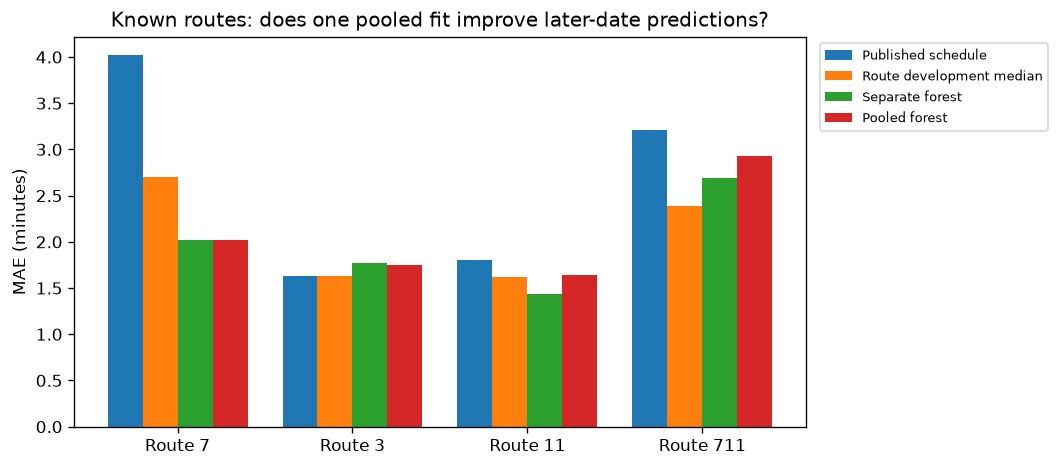

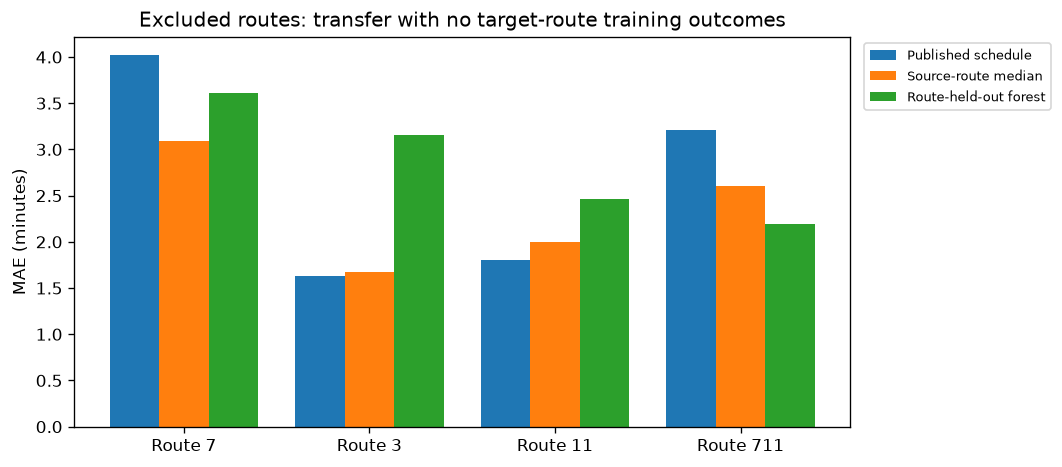

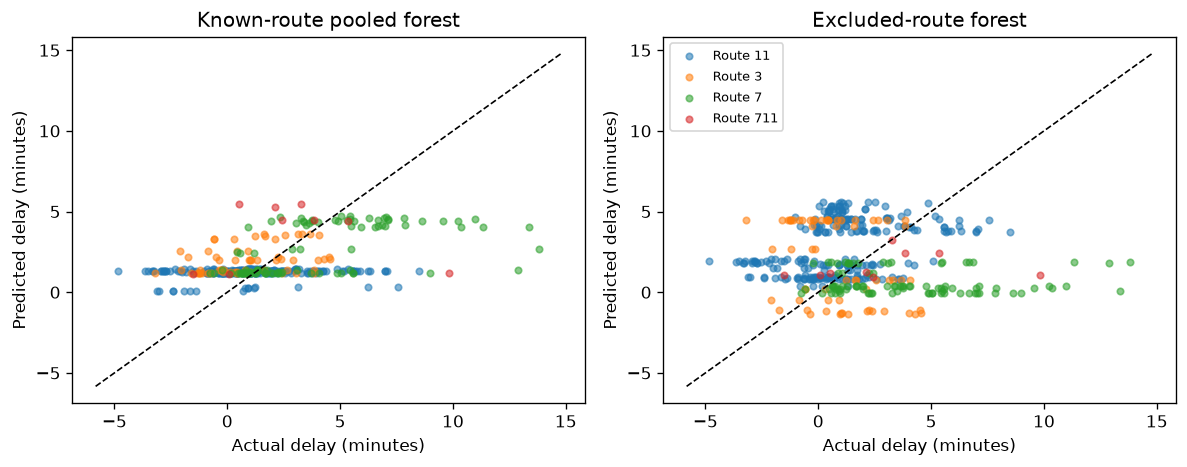

In [8]:
def plot_comparison(frame,methods,title):
    fig,ax = plt.subplots(figsize=(9,4));x=np.arange(len(frame));width=.8/len(methods)
    for j,method in enumerate(methods):
        ax.bar(x+(j-(len(methods)-1)/2)*width,frame[method],width,label=method)
    ax.set_xticks(x,["Route "+r for r in frame.index])
    ax.set(ylabel="MAE (minutes)",title=title)
    ax.legend(fontsize=8,loc="upper left",bbox_to_anchor=(1.01,1))
    fig.tight_layout();plt.show()

plot_comparison(known_comparison,["Published schedule","Route development median","Separate forest","Pooled forest"],
                "Known routes: does one pooled fit improve later-date predictions?")
plot_comparison(transfer_comparison,["Published schedule","Source-route median","Route-held-out forest"],
                "Excluded routes: transfer with no target-route training outcomes")

fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,frame,method,title in [(axes[0],known_predictions,"Pooled forest","Known-route pooled forest"),
                              (axes[1],transfer_predictions,"Route-held-out forest","Excluded-route forest")]:
    part=frame.loc[frame.method.eq(method)]
    for route,g in part.groupby("route"):
        ax.scatter(g.delay_minutes,g.predicted_delay_minutes,alpha=.55,s=15,label="Route "+route)
    low=min(part.delay_minutes.min(),part.predicted_delay_minutes.min())-1
    high=max(part.delay_minutes.max(),part.predicted_delay_minutes.max())+1
    ax.plot([low,high],[low,high],"k--",linewidth=1)
    ax.set(title=title,xlabel="Actual delay (minutes)",ylabel="Predicted delay (minutes)")
axes[1].legend(fontsize=8)
fig.tight_layout();plt.show()

## Reading the metrics: how much closer than the timetable?

The timetable is itself a prediction. We compare its average mistake with the model's average mistake on **the same arrivals**.

**Illustration, not a dataset observation:** scheduled at 10:00, predicted at 10:03, actually arrived at 10:04. The timetable misses by 4 minutes, the model by 1. Error is reduced by 3 minutes, or 75% of the original 4-minute error.

Across a dataset:

**Average error reduced (minutes) = timetable MAE − model MAE**  
**Average error reduced (seconds) = 60 × that difference**  
**MAE reduction (%) = 100 × (timetable MAE − model MAE) / timetable MAE**

Positive means better than the timetable; negative means worse. This percentage is **not accuracy**, is not a reduction in bus lateness, and is not the average of per-arrival percentage changes. It compares the two average errors.

**Prediction accuracy = percentage within ±2 minutes of actual arrival.** MAE/RMSE are minutes; R² is a separate squared-error comparison. Smaller MAE does not always mean a higher two-minute hit rate. Ordinary adjusted R² is meaningful for a fitted linear model, not a standard comparable diagnostic for a forest or median baseline.

In [9]:
# Add comparison metrics without changing the pooled model or its predictions.
timetable_mae = known_results.loc[known_results.method.eq("Published schedule")].set_index("route").MAE_minutes
def add_timetable_metrics(frame):
    result = frame.copy()
    result["timetable_MAE_minutes"] = result.route.map(timetable_mae)
    assert result.timetable_MAE_minutes.gt(0).all()
    result["average_error_reduced_minutes"] = result.timetable_MAE_minutes - result.MAE_minutes
    result["average_error_reduced_seconds"] = 60 * result.average_error_reduced_minutes
    result["MAE_reduction_vs_timetable_pct"] = 100 * result.average_error_reduced_minutes / result.timetable_MAE_minutes
    return result

known_results = add_timetable_metrics(known_results)
transfer_results = add_timetable_metrics(transfer_results)

def performance_view(frame,include_adjusted=False):
    columns = ["route","method","arrivals","MAE_minutes","RMSE_minutes","within_2_minutes_pct","R2"]
    if include_adjusted: columns += ["development_adjusted_R2"]
    return frame[columns].rename(columns={"route":"Route","method":"Approach","arrivals":"Test n",
        "MAE_minutes":"Test MAE (min)","RMSE_minutes":"Test RMSE (min)",
        "within_2_minutes_pct":"Test accuracy ±2 min (%)","R2":"Test R²",
        "development_adjusted_R2":"Development adjusted R²"}).round(3)

def improvement_view(frame):
    return frame[["route","method","timetable_MAE_minutes","MAE_minutes","average_error_reduced_minutes",
                  "average_error_reduced_seconds","MAE_reduction_vs_timetable_pct"]].rename(columns={
        "route":"Route","method":"Approach","timetable_MAE_minutes":"Timetable MAE (min)",
        "MAE_minutes":"Model MAE (min)","average_error_reduced_minutes":"Average error reduced (min)",
        "average_error_reduced_seconds":"Average error reduced (sec)",
        "MAE_reduction_vs_timetable_pct":"MAE reduction vs timetable (%)"}).round(3)

pooled_metrics = known_results.loc[known_results.method.eq("Pooled forest")].copy()
print("POOLED MODEL: test performance")
display(performance_view(pooled_metrics))
print("POOLED MODEL: how much closer than the timetable?")
display(improvement_view(pooled_metrics))

POOLED MODEL: test performance
POOLED MODEL: how much closer than the timetable?


,Route,Approach,Test n,Test MAE (min),Test RMSE (min),Test accuracy ±2 min (%),Test R²
3,7,Pooled forest,93,2.025,3.075,64.516,0.147
7,3,Pooled forest,64,1.750,2.074,59.375,-0.239
11,11,Pooled forest,244,1.637,2.205,70.082,0.012
15,711,Pooled forest,9,2.925,3.773,33.333,-0.442


,Route,Approach,Timetable MAE (min),Model MAE (min),Average error reduced (min),Average error reduced (sec),MAE reduction vs timetable (%)
3,7,Pooled forest,4.020,2.025,1.995,119.714,49.634
7,3,Pooled forest,1.629,1.750,-0.120,-7.219,-7.384
11,11,Pooled forest,1.799,1.637,0.161,9.685,8.973
15,711,Pooled forest,3.215,2.925,0.290,17.414,9.028


### Validation-winning route approaches: a distinct comparison

The main experiment compares **fixed individual forests** with one pooled forest. The discussion also requested the **approach with lowest validation MAE**: Route 7 median; Route 3 forest; Route 11 median; Route 711 direction-only backward-selected regression.

These are not identical to the training-fold-selected forest procedures in Notebook 9. This is an additional exploratory comparison. Route 711's fixed direction-only regression is refitted on its 110 development labels and evaluated on the same nine later arrivals. No test-driven feature choice is made.

Adjusted R² describes the regression's **development fit**, not its test predictions. It is N/A for forests and median baselines. Negative test R² means squared error exceeds the held-out-mean benchmark, not necessarily the timetable.

In [10]:
import statsmodels.api as sm

winner_rows = []
for route,method in [("7","Route development median"),("3","Separate forest"),("11","Route development median")]:
    row = known_results.loc[known_results.route.eq(route)&known_results.method.eq(method)].iloc[0].to_dict()
    row["development_adjusted_R2"] = "N/A"
    winner_rows.append(row)

# Use the subset chosen in the earlier Route 711 validation experiment: direction only.
a = development.loc[development.route.eq("711")]
b = evaluation.loc[evaluation.route.eq("711")]
x = pd.DataFrame({"const":1.,"direction_1":a.direction_id.eq("1").astype(float)},index=a.index)
z = pd.DataFrame({"const":1.,"direction_1":b.direction_id.eq("1").astype(float)},index=b.index)
direction_model = sm.OLS(a.delay_minutes,x).fit()
prediction = direction_model.predict(z)
row = score_prediction("711","Backward-selected regression",b.delay_minutes,prediction)
row["development_adjusted_R2"] = f"{direction_model.rsquared_adj:.3f}"
winner_rows.append(row)
validation_winner_test_metrics = add_timetable_metrics(pd.DataFrame(winner_rows))
print("VALIDATION-WINNING APPROACHES: test performance")
display(performance_view(validation_winner_test_metrics,include_adjusted=True))
print("VALIDATION-WINNING APPROACHES: how much closer than the timetable?")
display(improvement_view(validation_winner_test_metrics))
print("FIXED INDIVIDUAL FORESTS: timetable comparison")
display(improvement_view(known_results.loc[known_results.method.eq("Separate forest")]))
print("EXCLUDED-ROUTE TRANSFER: timetable comparison")
display(improvement_view(transfer_results.loc[transfer_results.method.eq("Route-held-out forest")]))

VALIDATION-WINNING APPROACHES: test performance
VALIDATION-WINNING APPROACHES: how much closer than the timetable?
FIXED INDIVIDUAL FORESTS: timetable comparison
EXCLUDED-ROUTE TRANSFER: timetable comparison


,Route,Approach,Test n,Test MAE (min),Test RMSE (min),Test accuracy ±2 min (%),Test R²,Development adjusted R²
0,7,Route development median,93,2.706,3.637,53.763,-0.192,N/A
1,3,Separate forest,64,1.772,2.203,57.812,-0.399,N/A
2,11,Route development median,244,1.617,2.219,72.131,-0.001,N/A
3,711,Backward-selected regression,9,2.479,3.618,66.667,-0.326,0.300


,Route,Approach,Timetable MAE (min),Model MAE (min),Average error reduced (min),Average error reduced (sec),MAE reduction vs timetable (%)
0,7,Route development median,4.020,2.706,1.314,78.855,32.694
1,3,Separate forest,1.629,1.772,-0.143,-8.574,-8.770
2,11,Route development median,1.799,1.617,0.182,10.926,10.124
3,711,Backward-selected regression,3.215,2.479,0.735,44.119,22.873


,Route,Approach,Timetable MAE (min),Model MAE (min),Average error reduced (min),Average error reduced (sec),MAE reduction vs timetable (%)
2,7,Separate forest,4.020,2.020,2.000,119.983,49.746
6,3,Separate forest,1.629,1.772,-0.143,-8.574,-8.770
10,11,Separate forest,1.799,1.440,0.359,21.513,19.933
14,711,Separate forest,3.215,2.696,0.519,31.155,16.152


,Route,Approach,Timetable MAE (min),Model MAE (min),Average error reduced (min),Average error reduced (sec),MAE reduction vs timetable (%)
2,7,Route-held-out forest,4.020,3.608,0.412,24.740,10.257
5,3,Route-held-out forest,1.629,3.154,-1.524,-91.451,-93.541
8,11,Route-held-out forest,1.799,2.464,-0.665,-39.885,-36.956
11,711,Route-held-out forest,3.215,2.198,1.017,61.024,31.637


### A visual explanation

Bars above zero mean fewer seconds of average error than the timetable; bars below zero mean more error. This is an error reduction, not an improvement in actual punctuality.

For Route 7, pooled MAE falls from about 4.02 to 2.02 minutes: roughly **2 minutes less average error**, or **49.6%**. That does not mean 49.6% accuracy. Its separate ±2-minute prediction accuracy is about 64.5%.

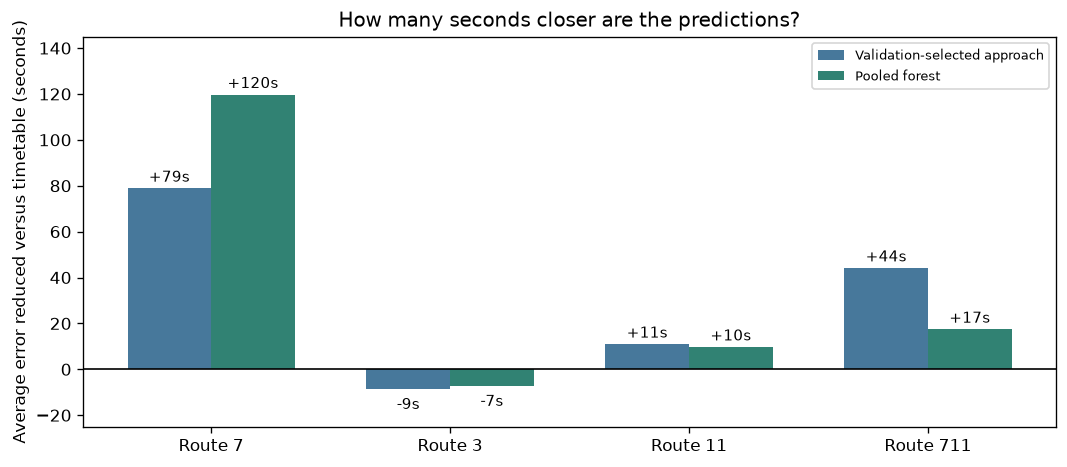

In [11]:
fig,ax = plt.subplots(figsize=(9,4))
routes = list(ROUTES)
x = np.arange(len(routes));width=.35
for offset,frame,label,color in [(-width/2,validation_winner_test_metrics,"Validation-selected approach","#47789b"),
                                  (width/2,pooled_metrics,"Pooled forest","#318273")]:
    values = frame.set_index("route").reindex(routes).average_error_reduced_seconds
    bars = ax.bar(x+offset,values,width,label=label,color=color)
    for bar,value in zip(bars,values):
        ax.annotate(f"{value:+.0f}s",(bar.get_x()+bar.get_width()/2,value),xytext=(0,4 if value>=0 else -12),
                    textcoords="offset points",ha="center",fontsize=9)
ax.axhline(0,color="black",linewidth=1)
ax.set_xticks(x,["Route "+r for r in routes])
ax.set(ylabel="Average error reduced versus timetable (seconds)",title="How many seconds closer are the predictions?")
ax.set_ylim(-25,145)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Suggested presentation wording

“We compare our predictions with the published timetable. A positive reduction means we were closer to the recorded arrival on average. On Route 7, the pooled model reduced average error by about two minutes. On Route 3, it increased average error by about seven seconds. This describes prediction performance, not a change in actual bus service.”

Each comparison uses identical evaluation records within a route. Route 711 has only nine arrivals on one day. Labels remain inferred; dates were already examined. Adding these metrics does not change the pooled model.

## 7. Results explained and questions answered



**These results are exploratory and conditional on inferred schedule labels.** The evaluation outcomes were already inspected in earlier project runs; this extension is not a fresh confirmatory test.



### Does one pooled model work on the four known routes?

- Route 7: pooled MAE **2.025 minutes**, separate forest **2.020**, timetable **4.020**, route median **2.706**. Pooling changes error relative to the separate fit by **-0.2% toward lower MAE**; a negative value means worse.

- Route 3: pooled MAE **1.750 minutes**, separate forest **1.772**, timetable **1.629**, route median **1.632**. Pooling changes error relative to the separate fit by **1.3% toward lower MAE**; a negative value means worse.

- Route 11: pooled MAE **1.637 minutes**, separate forest **1.440**, timetable **1.799**, route median **1.617**. Pooling changes error relative to the separate fit by **-13.7% toward lower MAE**; a negative value means worse.

- Route 711: pooled MAE **2.925 minutes**, separate forest **2.696**, timetable **3.215**, route median **2.388**. Pooling changes error relative to the separate fit by **-8.5% toward lower MAE**; a negative value means worse.



Pooling beats the separate forest on **1 of four routes**. Its equal-route-weight MAE is **2.084 minutes**, versus **1.982** for separate fits. Its equal-arrival-weight MAE is **1.771 minutes**. These summaries use different evaluation weights and should both be labeled.



### Does it transfer to an excluded route?

- Excluding Route 7: shared-feature forest MAE **3.608 minutes**, source-route median **3.096**, timetable **4.020**.

- Excluding Route 3: shared-feature forest MAE **3.154 minutes**, source-route median **1.674**, timetable **1.629**.

- Excluding Route 11: shared-feature forest MAE **2.464 minutes**, source-route median **2.002**, timetable **1.799**.

- Excluding Route 711: shared-feature forest MAE **2.198 minutes**, source-route median **2.607**, timetable **3.215**.



The route-held-out forest beats the timetable on **2 of four exclusions**. This is a different fitted pipeline from the route-aware pooled model. No held-route outcomes trained it, but **all held-out stop IDs were already represented on source routes**. This is new-route transfer at known sampled locations, not generalization to a new geography or the whole RTS system.



### Did we avoid look-ahead?

Known-route development ends before the earliest evaluation date across all routes. Each route-held-out fit excludes that route entirely and uses only source development dates strictly earlier than evaluation. Imputation, encoding, and route weights use training portions only. Scheduled headways may use later published timetable entries, which are available in advance; actual future observations never enter predictors.



### Why did we use different features for transfer?

Route-specific IDs cannot teach the behavior of an unseen category. Shared stop coordinates, scheduled elapsed/headway, time-of-day representation, and weekend status have meaningful values on an excluded route. This does not guarantee their numerical ranges or operating conditions are covered. The audit table flags out-of-range cases; when Route 711 is excluded, source data contain no weekends.



### Should we replace the separate models?

A single interface is convenient, but replacement needs a consistent, meaningful benefit against route medians and separate fits on genuinely new dates. The current fixed depth/weighting is one transparent experiment, not a claim of optimal capacity or weights. Do not tune repeatedly against these same outcomes and then describe them as untouched.



### Is the generalized-model task completed?

We fitted a usable known-route pooled pipeline and ran a separate chronological route-exclusion experiment. A verified operational model or a universal unseen-route predictor is not established. Labels remain provisional, the locations overlap, independent operating days are few, and Route 711 has nine evaluation arrivals on one day.



### What is the next defensible step?

Keep these outputs as exploratory evidence. Resolve schedule-link concerns and collect a new evaluation period, especially more weekend/evening days and additional locations. Predeclare the model/weighting/selection rules before using that period. No additional model tuning is needed to present this experiment.



**Sources:** same original workbooks and archived GTFS as Notebook 9. Richard Borzi / University of Florida, supplied by Gainesville RTS, CC BY 4.0. Route records: [7](https://zenodo.org/records/10034933), [3](https://zenodo.org/records/10034688), [11](https://zenodo.org/records/10034723), [711](https://zenodo.org/records/10034622). [Historical GTFS](https://www.ftis.org/PostFileDownload.aspx?id=602A0).
### Practical conclusion from this experiment

The pooled model's arrival-weighted MAE is **1.77 minutes**, versus **1.65 minutes** for the separate forests. The equal-route average is **2.08 versus 1.98 minutes**. Route 3's small pooling gain is only about **1.4 seconds**; Route 7 is effectively tied, while Routes 11 and 711 worsen. This supports keeping separate fits as the stronger current benchmark, not claiming that all possible pooled models must fail.

One shared model offers a simpler artifact to maintain, but it does not automatically improve prediction. Data heterogeneity, the fixed tree capacity, and the selected route weighting are possible contributors; this experiment does not isolate their causes. We do not tune them after inspecting these outcomes.

For unseen-route transfer, the schedule is beaten on two exclusions. All evaluated stop IDs are already present on other routes, and Route 711 has only nine evaluation arrivals. This is insufficient evidence for reliable prediction on genuinely new routes, new locations, or a new operating period.

The supplied `predict_pooled.py` reloads the saved known-route model using its manifest and demonstrates a prediction. Supply an actual published scheduled arrival; the helper does not query a service calendar or a live feed. An unseen route requires a separate transfer experiment, not simply bypassing the known-route checks.


## Optional - save the trained model and result tables

Uncomment to save outputs beside this notebook. The supplied download includes the trained pooled pipeline and a manifest describing its inputs and scope. It predicts delay in minutes; add that value to the scheduled arrival. Only load model files you created or trust. The original sources remain unchanged.

In [12]:
# joblib.dump(pooled_model,"RTS_Pooled_Known_Routes.joblib")
# known_results.to_csv("RTS_Pooled_Known_Route_Results.csv",index=False)
# transfer_results.to_csv("RTS_Route_Heldout_Results.csv",index=False)
# transfer_audit.to_csv("RTS_Transfer_Coverage_Audit.csv",index=False)